In [ ]:
!pip install xgboost

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier


In [23]:
df=pd.read_csv("titanic.csv")

In [24]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [26]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [27]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [28]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [29]:
df=df.dropna(subset=["Embarked"])

In [30]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [31]:
df["Sex"].unique()

array(['male', 'female'], dtype=object)

In [32]:
df["Embarked"].unique()

array(['S', 'C', 'Q'], dtype=object)

In [33]:
df["Cabin"].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'C83', 'F33', 'F G73',
       'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101', 'F E69',
       'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4', 'A32',
       'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35', 'C87',
       'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19', 'B49',
       'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54', 'B57 B59 B63 B66',
       'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40', 'T', 'C128',
       'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44', 'A34', 'C104',
       'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14', 'B37', 'C30',
       'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38', 'B39', 'B22',
       'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68', 'B41', 'A20',
       'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48', 'E58', 'C126',
       'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63', 'C62 C64',
       'E24',

In [34]:
df=df.drop(columns=['Cabin'])

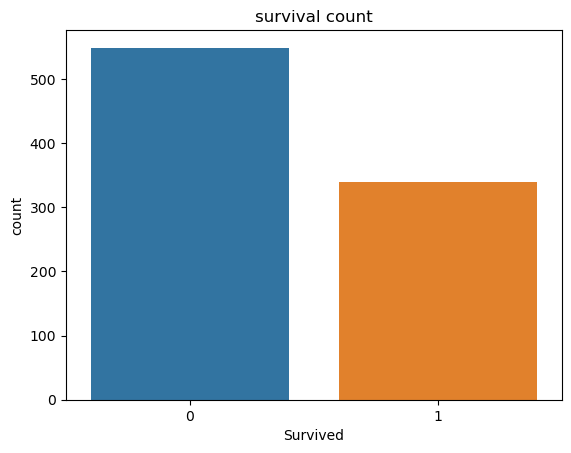

In [35]:
#target variable 
sns.countplot(x='Survived',data=df)
plt.title("survival count")
plt.show()

In [36]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object


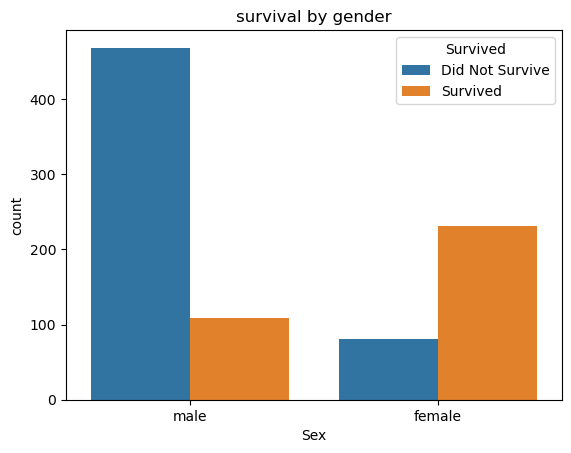

In [37]:
df_plot = df.copy()

df_plot["Survived"] = df_plot["Survived"].map({
    0: "Did Not Survive",
    1: "Survived"
})
sns.countplot(x='Sex', hue='Survived', data=df_plot)
plt.title("survival by gender")
plt.show()

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


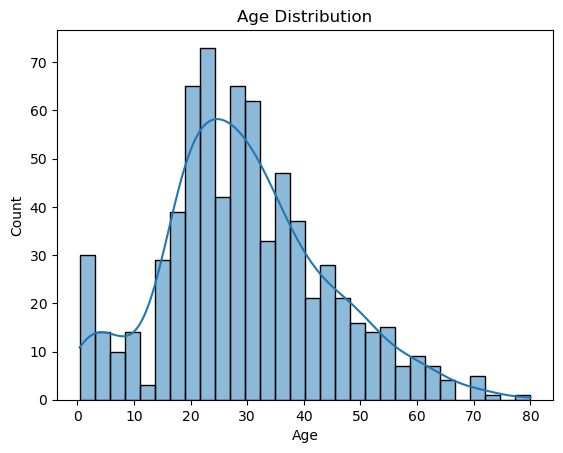

In [38]:
'''kde=True
KDE stands for Kernel Density Estimation.
It draws a smooth density curve over the histogram.'''
sns.histplot(df['Age'],bins=30,kde=True)
plt.title("Age Distribution")
plt.show()

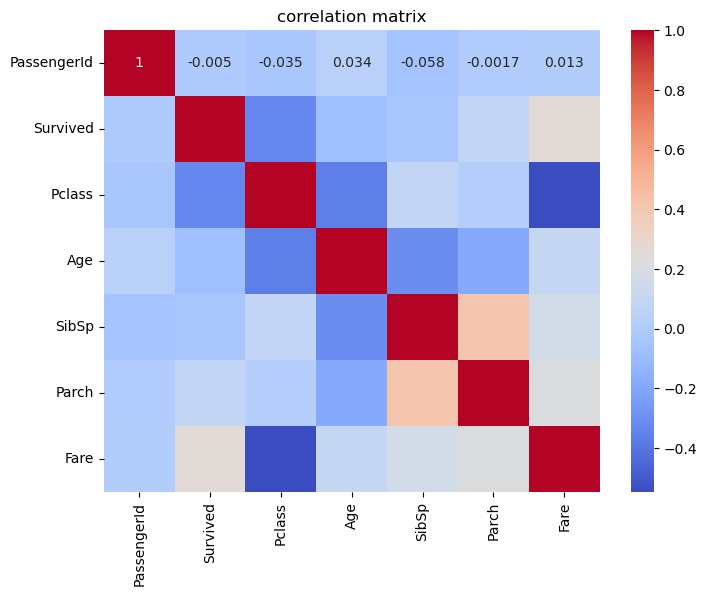

In [39]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True,cmap='coolwarm')
plt.title("correlation matrix")
plt.show()

In [40]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [41]:
le_Sex=LabelEncoder()
oe_Embarked=OneHotEncoder(sparse_output=False)

In [42]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [43]:
X=df[['Pclass','Sex', 'Age', 'SibSp','Parch','Fare', 'Embarked']]

In [44]:
y=df['Survived']

In [45]:
#counts how many times each class appears in the target variable.
y.value_counts()

Survived
0    549
1    340
Name: count, dtype: int64

In [46]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [47]:
# Apply Label Encoding to the binary 'Sex' feature
X_train['Sex']=le_Sex.fit_transform(X_train['Sex'])
# Apply One-Hot Encoding to the categorical 'Embarked' feature
onehotencoded=oe_Embarked.fit_transform(X_train[['Embarked']])

In [48]:
onehotencoded

array([[0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.],
       ...,
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.]])

In [49]:
#the names of the new columns created by the OneHotEncoder.
oe_Embarked.get_feature_names_out(['Embarked'])

array(['Embarked_C', 'Embarked_Q', 'Embarked_S'], dtype=object)

In [50]:
'''This line converts the One-Hot Encoded output into a Pandas DataFrame with meaningful column names and the correct row indices.'''
encoded_df=pd.DataFrame(onehotencoded,columns=oe_Embarked.get_feature_names_out(['Embarked']),index=X_train.index)

In [51]:
X_train=X_train.drop(columns=['Embarked'])

In [52]:
'''There are only two possibilities:

axis=0 → Rows (vertical direction)
axis=1 → Columns (horizontal direction)'''


X_train=pd.concat([X_train,encoded_df],axis=1)

In [53]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
621,1,1,42.0,1,0,52.5542,0.0,0.0,1.0
481,2,1,NaN,0,0,0.0000,0.0,0.0,1.0
527,1,1,NaN,0,0,221.7792,0.0,0.0,1.0
435,1,0,14.0,1,2,120.0000,0.0,0.0,1.0
797,3,0,31.0,0,0,8.6833,0.0,0.0,1.0


In [54]:
#he same Label Encoding learned from the training data to the Sex column in the test data.
X_test['Sex']=le_Sex.transform(X_test['Sex'])

In [55]:
#applies the same One-Hot Encoding learned from the training data to the Embarked column in the test dataset.
onehot_test=oe_Embarked.transform(X_test[['Embarked']])

In [56]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
621,1,1,42.0,1,0,52.5542,0.0,0.0,1.0
481,2,1,NaN,0,0,0.0000,0.0,0.0,1.0
527,1,1,NaN,0,0,221.7792,0.0,0.0,1.0
435,1,0,14.0,1,2,120.0000,0.0,0.0,1.0
797,3,0,31.0,0,0,8.6833,0.0,0.0,1.0


In [57]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 711 entries, 621 to 507
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      711 non-null    int64  
 1   Sex         711 non-null    int32  
 2   Age         571 non-null    float64
 3   SibSp       711 non-null    int64  
 4   Parch       711 non-null    int64  
 5   Fare        711 non-null    float64
 6   Embarked_C  711 non-null    float64
 7   Embarked_Q  711 non-null    float64
 8   Embarked_S  711 non-null    float64
dtypes: float64(5), int32(1), int64(3)
memory usage: 52.8 KB


In [58]:
X_train.isnull().sum()

Pclass          0
Sex             0
Age           140
SibSp           0
Parch           0
Fare            0
Embarked_C      0
Embarked_Q      0
Embarked_S      0
dtype: int64

In [59]:
'''
n_estimators=100 – Number of trees (boosting rounds) to build.
learning_rate=0.1 – Controls how much each tree contributes to the final model.
max_depth=3 – Maximum depth of each decision tree.
subsample=0.8 – Fraction of training samples used to build each tree.
colsample_bytree=0.8 – Fraction of features used to build each tree.
min_child_weight=1 – Minimum sum of instance weights required in a child node before further splitting.
gamma=0 – Minimum loss reduction required to create a new split.
reg_alpha=0 – L1 regularization parameter to reduce overfitting.
reg_lambda=1 – L2 regularization parameter to improve model generalization.
random_state=42 – Sets a fixed random seed to ensure reproducible results'''

model=XGBClassifier(n_estimators=100, learning_rate=0.1,max_depth=3,subsample=0.8,colsample_bytree=0.8,min_child_Weight=1,
                    gamma=0,reg_Alpha=0,reg_lambda=1,random_state=42)

In [60]:
model.fit(X_train,y_train)

C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:200: UserWarning: [23:10:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "min_child_Weight", "reg_Alpha" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_Weight=1, min_child_weight=None,
              missing=nan, monotone_constraints=None, multi_strategy=None,
              n_estimators=100, n_jobs=None, ...)

In [61]:
encoded_test_df=pd.DataFrame(onehot_test,columns=oe_Embarked.get_feature_names_out(['Embarked']),index=X_test.index)

In [62]:
X_test=X_test.drop(columns=['Embarked'])

In [63]:
X_test=pd.concat([X_test,encoded_test_df],axis=1)

In [64]:
X_test['Sex'] 

160    1
126    1
428    1
422    1
565    1
      ..
39     0
91     1
883    1
853    0
637    1
Name: Sex, Length: 178, dtype: int32

In [65]:
y_pred = model.predict(X_test)

In [66]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8426966292134831


In [67]:
print(confusion_matrix(y_test, y_pred))

[[101   9]
 [ 19  49]]


In [68]:
cm=confusion_matrix(y_test,y_pred)

In [69]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.92      0.88       110
           1       0.84      0.72      0.78        68

    accuracy                           0.84       178
   macro avg       0.84      0.82      0.83       178
weighted avg       0.84      0.84      0.84       178



In [70]:
plt.figure(figsize=(5,4))

<Figure size 500x400 with 0 Axes>

<Figure size 500x400 with 0 Axes>

<Axes: >

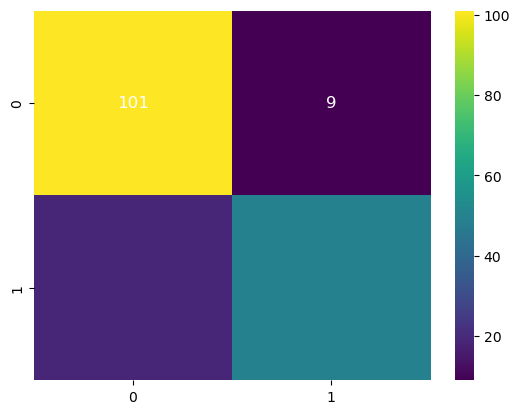

In [71]:
sns.heatmap(cm,annot=True,fmt='d',cmap='viridis',annot_kws={"color":"white","fontsize":12})

In [72]:
plt.show()

In [73]:
y_test.unique()

array([0, 1], dtype=int64)

In [74]:
cm

array([[101,   9],
       [ 19,  49]], dtype=int64)

101 (0.5, 0.5)
9 (1.5, 0.5)


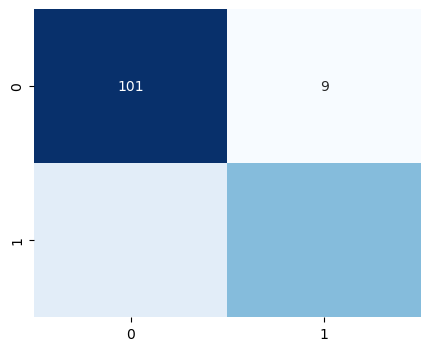

In [75]:
fig, ax = plt.subplots(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    ax=ax
)

for text in ax.texts:
    print(text.get_text(), text.get_position())

<Figure size 800x600 with 0 Axes>

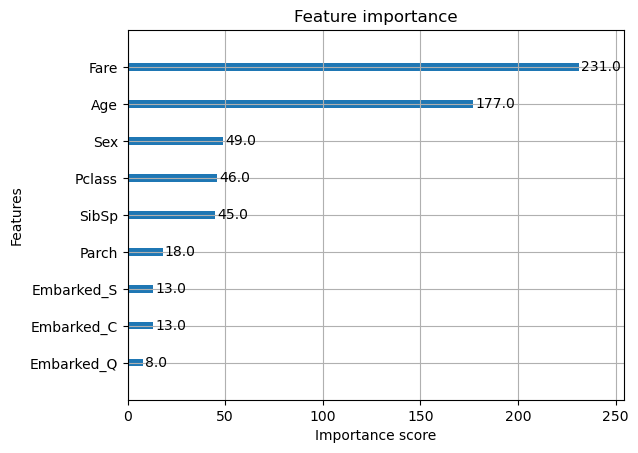

In [76]:
#plot feature importance
from xgboost import plot_importance
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plot_importance(model)
plt.show()

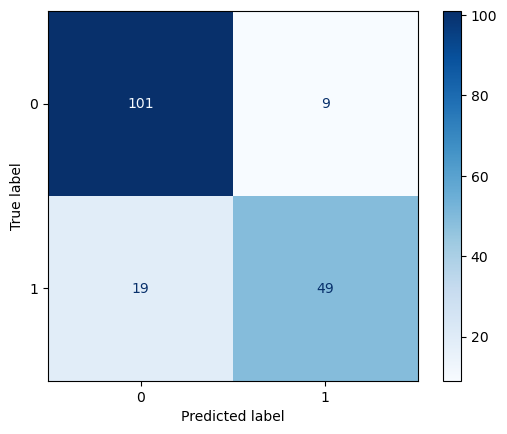

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
plt.show()